Import libraries and configure visualisation


In [1]:
# ============================================================
# 1. IMPORT LIBRARIES AND CONFIGURATION
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import os
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    silhouette_score,
    balanced_accuracy_score,
    davies_bouldin_score
)

from sklearn.inspection import permutation_importance

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Custom colour palette
COLORS = {
    "purple": "#7B2CBF",
    "violet": "#5A189A",
    "pink": "#F15BB5",
    "cyan": "#00B4D8",
    "teal": "#00A896",
    "green": "#80B918",
    "orange": "#F77F00",
    "yellow": "#F9C74F",
    "red": "#D62828",
    "blue": "#4361EE",
    "dark": "#20243A",
    "grey": "#6C757D"
}

PALETTE = [
    COLORS["purple"],
    COLORS["cyan"],
    COLORS["pink"],
    COLORS["orange"],
    COLORS["teal"],
    COLORS["green"],
    COLORS["blue"],
    COLORS["yellow"]
]

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette=PALETTE,
    rc={
        "figure.figsize": (11, 6),
        "axes.titleweight": "bold",
        "axes.titlesize": 15,
        "axes.labelsize": 11,
        "grid.alpha": 0.20,
        "axes.spines.top": False,
        "axes.spines.right": False
    }
)

print("Libraries imported successfully.")

Libraries imported successfully.


Load data


In [2]:
# ============================================================
# 2. LOAD DATASET
# ============================================================

file_path = "netflix_user_behavior_dataset.csv"

if not os.path.exists(file_path):
    alternative_path = "/mnt/data/netflix_user_behavior_dataset.csv"

    if os.path.exists(alternative_path):
        file_path = alternative_path
    else:
        raise FileNotFoundError(
            "Dataset not found. Place the CSV file in the notebook directory."
        )

df = pd.read_csv(file_path)

print("Dataset successfully loaded.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset successfully loaded.
Rows: 50000
Columns: 20


,user_id,age,gender,country,account_age_months,subscription_type,monthly_fee,payment_method,primary_device,devices_used,favorite_genre,avg_watch_time_minutes,watch_sessions_per_week,binge_watch_sessions,completion_rate,rating_given,content_interactions,recommendation_click_rate,days_since_last_login,churned
0,U100000,56,Male,India,17,Standard,15.99,PayPal,Laptop,1,Sci-Fi,220,17,3,60,1.7,5,66,16,No
1,U100001,46,Female,USA,20,Standard,12.99,PayPal,Tablet,2,Documentary,76,15,4,71,4.6,7,78,14,No
2,U100002,32,Other,USA,25,Basic,15.99,PayPal,Tablet,2,Comedy,215,6,13,33,2.0,27,29,41,No
3,U100003,60,Male,Canada,37,Standard,12.99,PayPal,Smart TV,3,Action,280,4,9,58,1.2,9,23,22,No
4,U100004,25,Male,Brazil,23,Premium,12.99,PayPal,Mobile,3,Horror,261,15,9,64,1.3,49,56,54,No


Dataset overview

In [3]:
# ============================================================
# 3. DATASET OVERVIEW
# ============================================================

print("DATASET INFORMATION")
print("-" * 60)

df.info()

print("\nSTATISTICAL SUMMARY")
display(df.describe().T)

print("\nCATEGORICAL SUMMARY")
display(df.describe(include="object").T)

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nDATASET DIMENSIONS")
print(df.shape)

DATASET INFORMATION
------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   user_id                    50000 non-null  object 
 1   age                        50000 non-null  int64  
 2   gender                     50000 non-null  object 
 3   country                    50000 non-null  object 
 4   account_age_months         50000 non-null  int64  
 5   subscription_type          50000 non-null  object 
 6   monthly_fee                50000 non-null  float64
 7   payment_method             50000 non-null  object 
 8   primary_device             50000 non-null  object 
 9   devices_used               50000 non-null  int64  
 10  favorite_genre             50000 non-null  object 
 11  avg_watch_time_minutes     50000 non-null  int64  
 12  watch_sessions_per_we

,count,mean,std,min,25%,50%,75%,max
age,50000.0,40.979240,13.528733,18.00,29.00,41.00,53.00,64.00
account_age_months,50000.0,29.874000,17.051104,1.00,15.00,30.00,45.00,59.00
monthly_fee,50000.0,12.323340,3.309109,7.99,7.99,12.99,15.99,15.99
devices_used,50000.0,1.999140,0.818238,1.00,1.00,2.00,3.00,3.00
avg_watch_time_minutes,50000.0,154.946520,83.727292,10.00,83.00,155.00,228.00,299.00
watch_sessions_per_week,50000.0,9.986920,5.480616,1.00,5.00,10.00,15.00,19.00
binge_watch_sessions,50000.0,7.002520,4.335819,0.00,3.00,7.00,11.00,14.00
completion_rate,50000.0,64.533420,20.206377,30.00,47.00,65.00,82.00,99.00
rating_given,50000.0,3.002316,1.152308,1.00,2.00,3.00,4.00,5.00
content_interactions,50000.0,24.306380,14.468037,0.00,12.00,24.00,37.00,49.00



CATEGORICAL SUMMARY


,count,unique,top,freq
user_id,50000,50000,U100000,1
gender,50000,3,Female,16759
country,50000,10,Brazil,5116
subscription_type,50000,3,Standard,19931
payment_method,50000,4,PayPal,12539
primary_device,50000,4,Mobile,12585
favorite_genre,50000,8,Documentary,6352
churned,50000,2,No,40036



COLUMN NAMES
['user_id', 'age', 'gender', 'country', 'account_age_months', 'subscription_type', 'monthly_fee', 'payment_method', 'primary_device', 'devices_used', 'favorite_genre', 'avg_watch_time_minutes', 'watch_sessions_per_week', 'binge_watch_sessions', 'completion_rate', 'rating_given', 'content_interactions', 'recommendation_click_rate', 'days_since_last_login', 'churned']

DATASET DIMENSIONS
(50000, 20)


Data quality analysis

Missing values:


,Missing Values
user_id,0
age,0
days_since_last_login,0
recommendation_click_rate,0
content_interactions,0
rating_given,0
completion_rate,0
binge_watch_sessions,0
watch_sessions_per_week,0
avg_watch_time_minutes,0


Duplicate rows: 0
Duplicate user IDs: 0


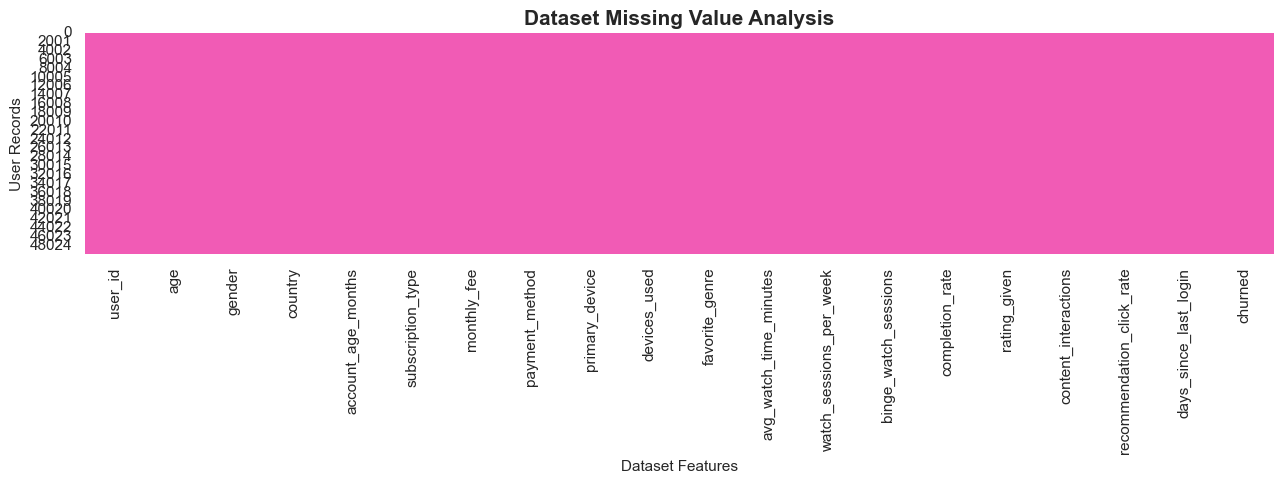

In [4]:
# ============================================================
# 4. DATA QUALITY ANALYSIS
# ============================================================

print("Missing values:")
display(
    df.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)

print("Duplicate rows:", df.duplicated().sum())

if "user_id" in df.columns:
    print("Duplicate user IDs:", df["user_id"].duplicated().sum())

# Missing value visualisation
plt.figure(figsize=(13, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap=sns.color_palette(
        ["#F15BB5", "#F8F7FF"],
        as_cmap=True
    )
)

plt.title("Dataset Missing Value Analysis")
plt.xlabel("Dataset Features")
plt.ylabel("User Records")
plt.tight_layout()
plt.show()

5. Data preprocessing

In [5]:
# ============================================================
# 5. DATA CLEANING
# ============================================================

df = df.copy()

# Remove duplicate user records
if "user_id" in df.columns:
    df = df.drop_duplicates(
        subset=["user_id"],
        keep="first"
    )

# Clean categorical values
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].astype("string").str.strip()

# Convert numerical columns
numerical_columns = [
    "age",
    "account_age_months",
    "monthly_fee",
    "devices_used",
    "avg_watch_time_minutes",
    "watch_sessions_per_week",
    "binge_watch_sessions",
    "completion_rate",
    "rating_given",
    "content_interactions",
    "recommendation_click_rate",
    "days_since_last_login"
]

for col in numerical_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Clean target variable
df["churned"] = df["churned"].astype("string").str.strip().str.title()

# Convert target into binary format
df["churn"] = df["churned"].map({
    "No": 0,
    "Yes": 1
})

if df["churn"].isna().any():
    raise ValueError("Unexpected or missing churn labels. Check the churned column.")

print("Data preprocessing completed.")
print("Cleaned dataset shape:", df.shape)

display(df.head())

Data preprocessing completed.
Cleaned dataset shape: (50000, 21)


,user_id,age,gender,country,account_age_months,subscription_type,monthly_fee,payment_method,primary_device,devices_used,...,avg_watch_time_minutes,watch_sessions_per_week,binge_watch_sessions,completion_rate,rating_given,content_interactions,recommendation_click_rate,days_since_last_login,churned,churn
0,U100000,56,Male,India,17,Standard,15.99,PayPal,Laptop,1,...,220,17,3,60,1.7,5,66,16,No,0
1,U100001,46,Female,USA,20,Standard,12.99,PayPal,Tablet,2,...,76,15,4,71,4.6,7,78,14,No,0
2,U100002,32,Other,USA,25,Basic,15.99,PayPal,Tablet,2,...,215,6,13,33,2.0,27,29,41,No,0
3,U100003,60,Male,Canada,37,Standard,12.99,PayPal,Smart TV,3,...,280,4,9,58,1.2,9,23,22,No,0
4,U100004,25,Male,Brazil,23,Premium,12.99,PayPal,Mobile,3,...,261,15,9,64,1.3,49,56,54,No,0


Churn distribution analysis

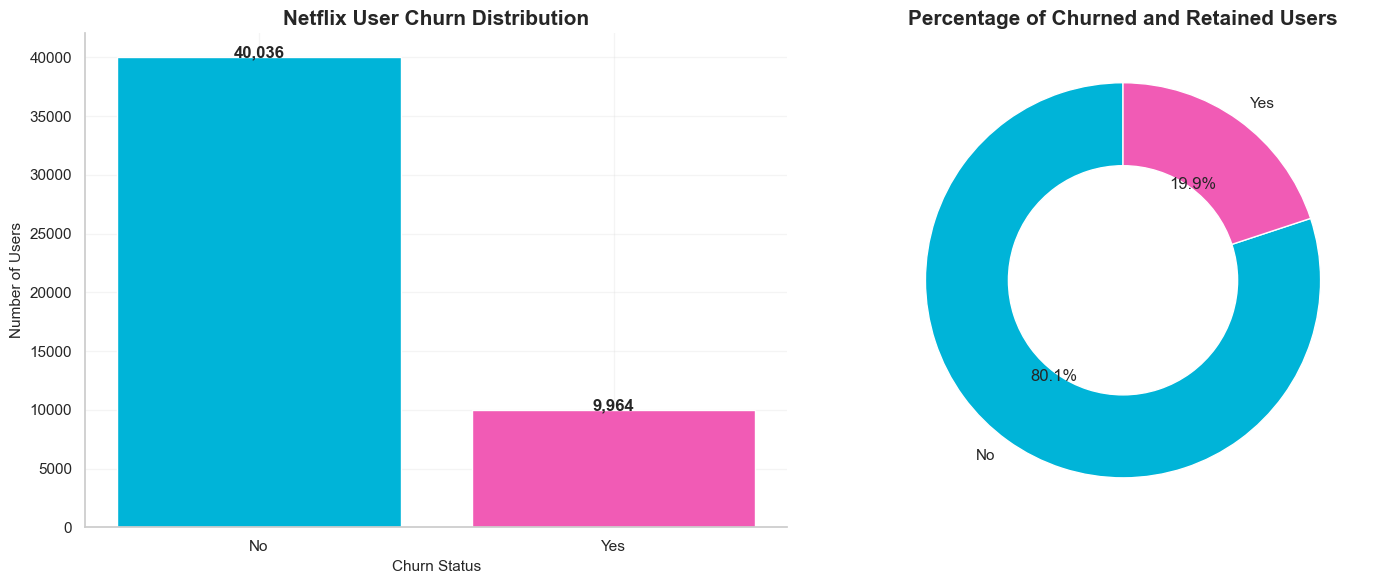

Overall churn rate: 19.93 %


In [6]:
# ============================================================
# 6. CHURN DISTRIBUTION
# ============================================================

churn_counts = df["churned"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Bar chart
axes[0].bar(
    churn_counts.index,
    churn_counts.values,
    color=[COLORS["cyan"], COLORS["pink"]][:len(churn_counts)]
)

axes[0].set_title("Netflix User Churn Distribution")
axes[0].set_xlabel("Churn Status")
axes[0].set_ylabel("Number of Users")

for i, value in enumerate(churn_counts.values):
    axes[0].text(
        i,
        value,
        f"{value:,}",
        ha="center",
        fontweight="bold"
    )

# Donut chart
axes[1].pie(
    churn_counts.values,
    labels=churn_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=[COLORS["cyan"], COLORS["pink"]][:len(churn_counts)],
    wedgeprops={"width": 0.42, "edgecolor": "white"}
)

axes[1].set_title("Percentage of Churned and Retained Users")

plt.tight_layout()
plt.show()

print("Overall churn rate:", round(df["churn"].mean() * 100, 2), "%")

7.Numerical feature distributions


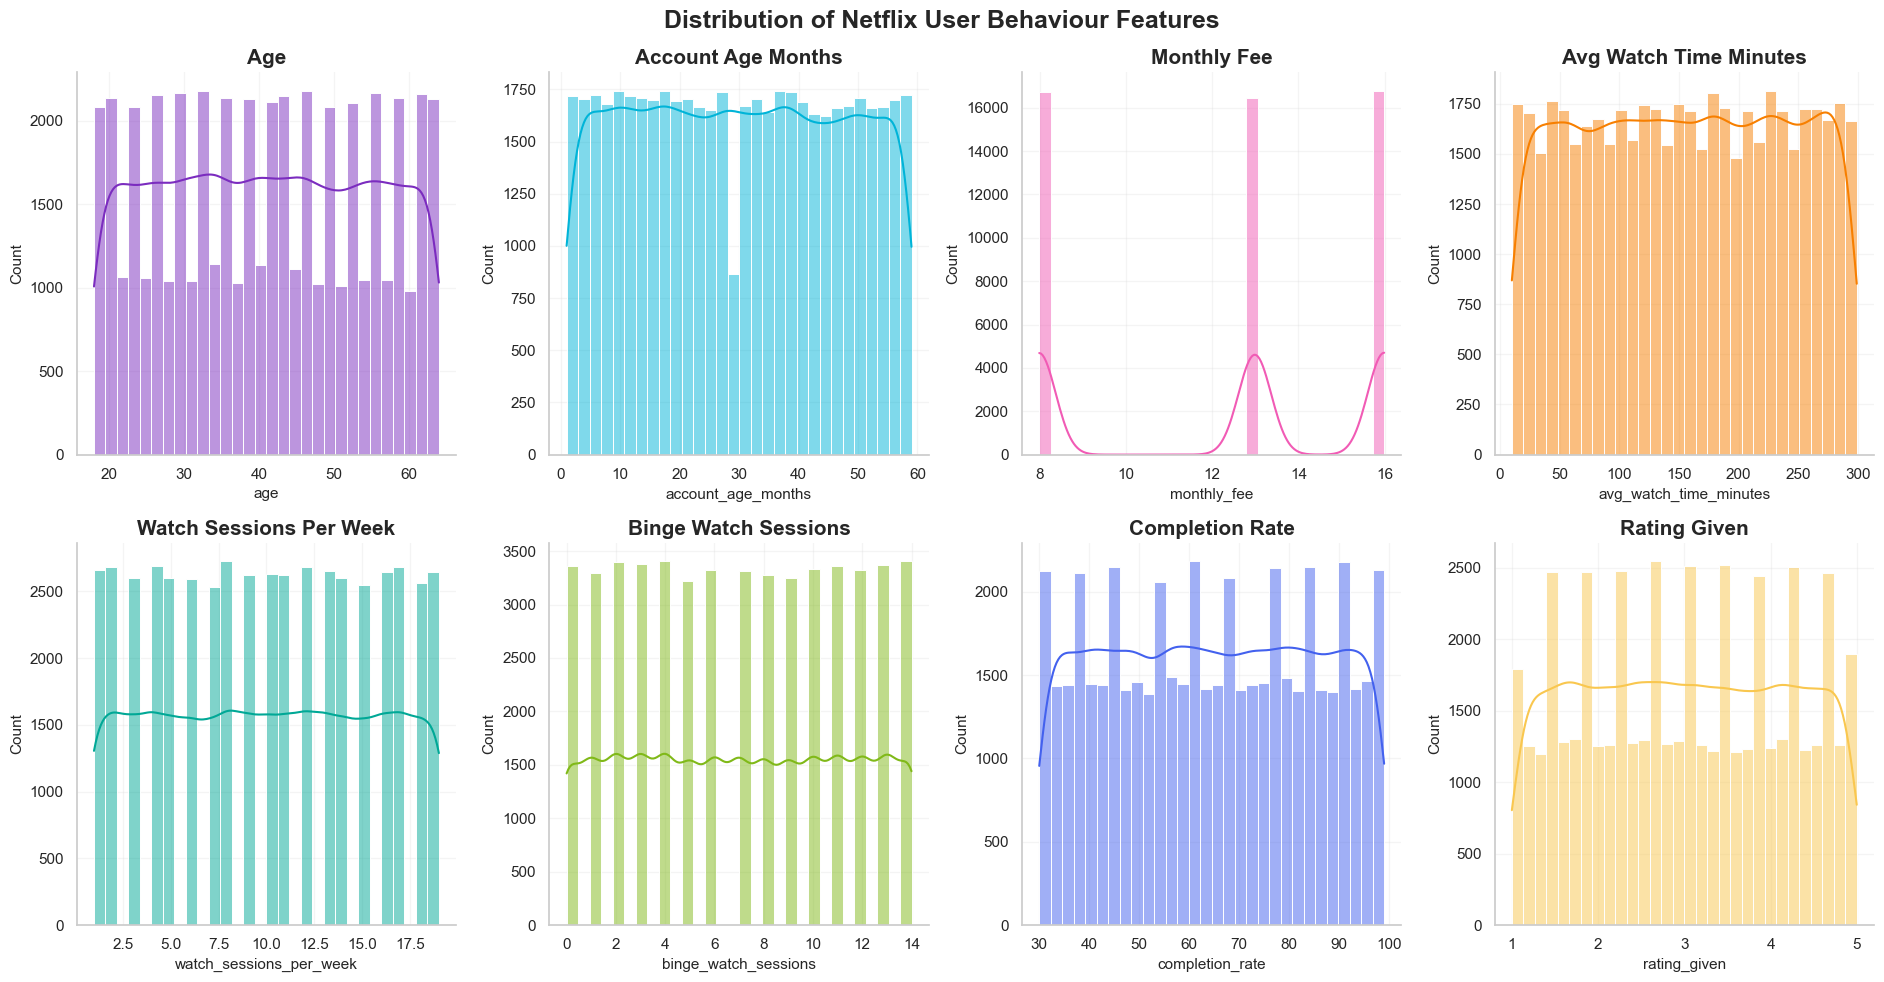

In [7]:
# ============================================================
# 7. NUMERICAL FEATURE DISTRIBUTION
# ============================================================

features = [
    "age",
    "account_age_months",
    "monthly_fee",
    "avg_watch_time_minutes",
    "watch_sessions_per_week",
    "binge_watch_sessions",
    "completion_rate",
    "rating_given"
]

fig, axes = plt.subplots(2, 4, figsize=(19, 10))

for ax, feature, color in zip(
    axes.flatten(),
    features,
    PALETTE
):
    sns.histplot(
        df[feature].dropna(),
        kde=True,
        bins=30,
        color=color,
        ax=ax
    )

    ax.set_title(feature.replace("_", " ").title())

plt.suptitle(
    "Distribution of Netflix User Behaviour Features",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

8. Subscription analysis

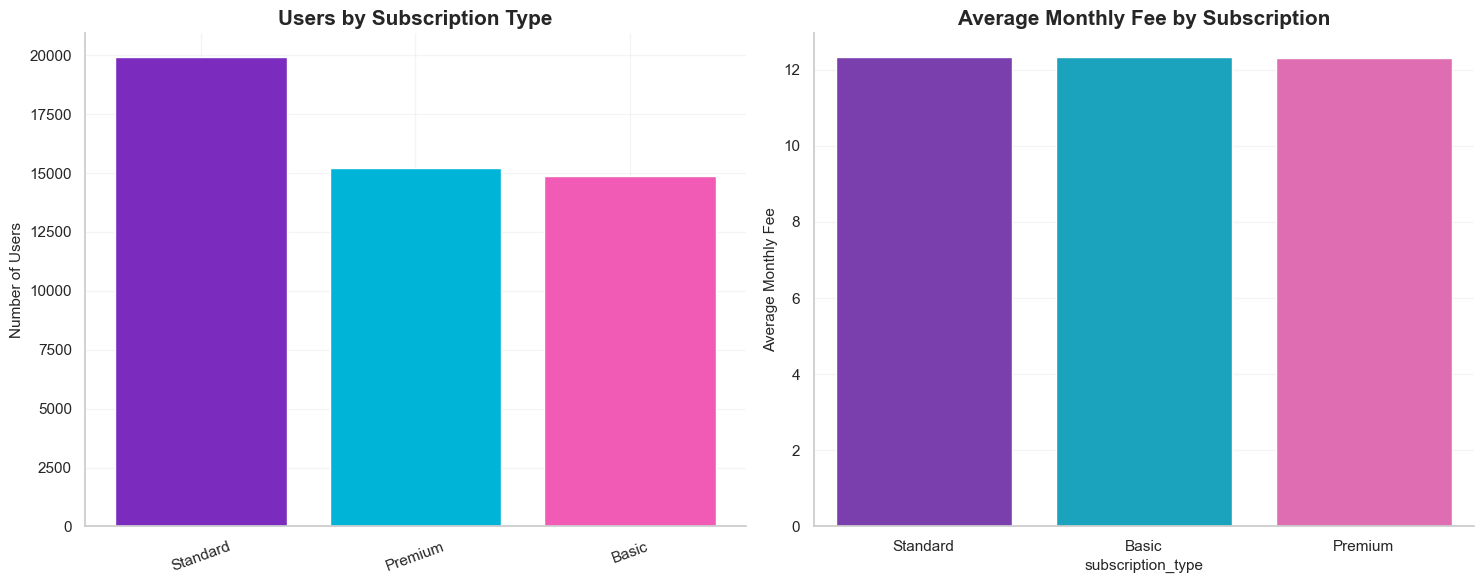

In [8]:
# ============================================================
# 8. SUBSCRIPTION ANALYSIS
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subscription type distribution
subscription_counts = df["subscription_type"].value_counts()

axes[0].bar(
    subscription_counts.index,
    subscription_counts.values,
    color=PALETTE[:len(subscription_counts)]
)

axes[0].set_title("Users by Subscription Type")
axes[0].set_ylabel("Number of Users")
axes[0].tick_params(axis="x", rotation=20)

# Average monthly fee
sns.barplot(
    data=df,
    x="subscription_type",
    y="monthly_fee",
    estimator="mean",
    errorbar=None,
    palette=PALETTE,
    ax=axes[1]
)

axes[1].set_title("Average Monthly Fee by Subscription")
axes[1].set_ylabel("Average Monthly Fee")

plt.tight_layout()
plt.show()

9. Churn analysis by subscription type

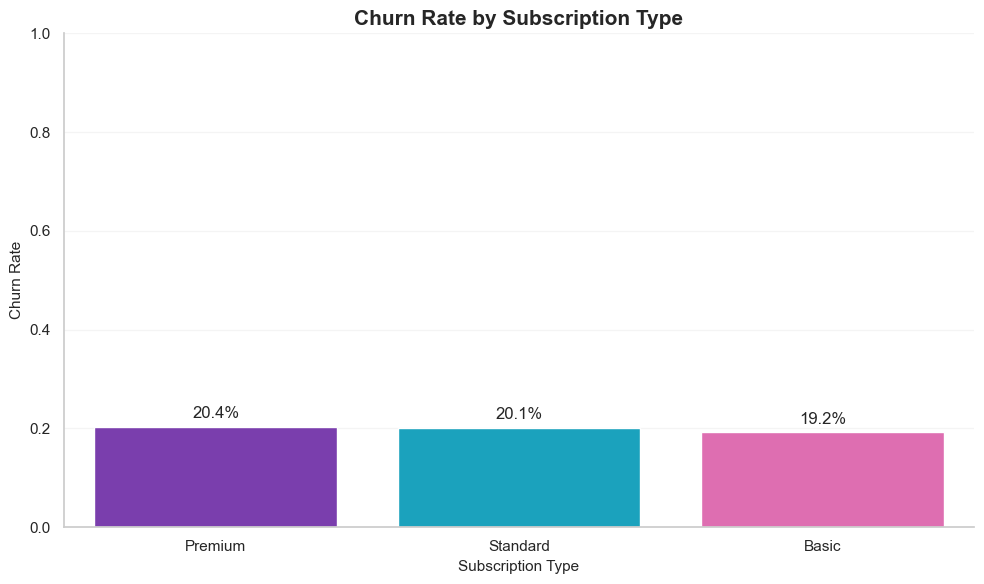

In [9]:
# ============================================================
# 9. CHURN BY SUBSCRIPTION TYPE
# ============================================================

subscription_churn = (
    df.groupby("subscription_type")["churn"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=subscription_churn,
    x="subscription_type",
    y="churn",
    palette=PALETTE
)

ax.set_title("Churn Rate by Subscription Type")
ax.set_ylabel("Churn Rate")
ax.set_xlabel("Subscription Type")
ax.set_ylim(0, 1)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        labels=[f"{v*100:.1f}%" for v in container.datavalues],
        padding=4
    )

plt.tight_layout()
plt.show()

10. Genre and content preference analysis

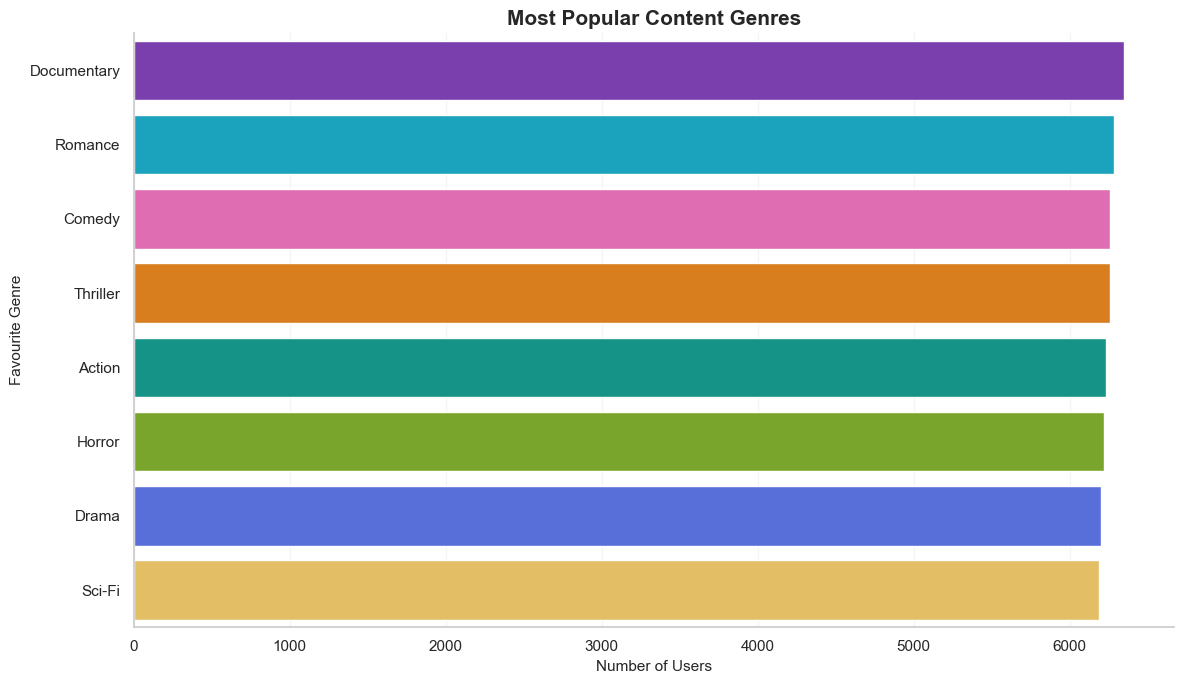

In [10]:
# ============================================================
# 10. GENRE ANALYSIS
# ============================================================

genre_counts = df["favorite_genre"].value_counts()

plt.figure(figsize=(12, 7))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index,
    palette=PALETTE
)

plt.title("Most Popular Content Genres")
plt.xlabel("Number of Users")
plt.ylabel("Favourite Genre")

plt.tight_layout()
plt.show()

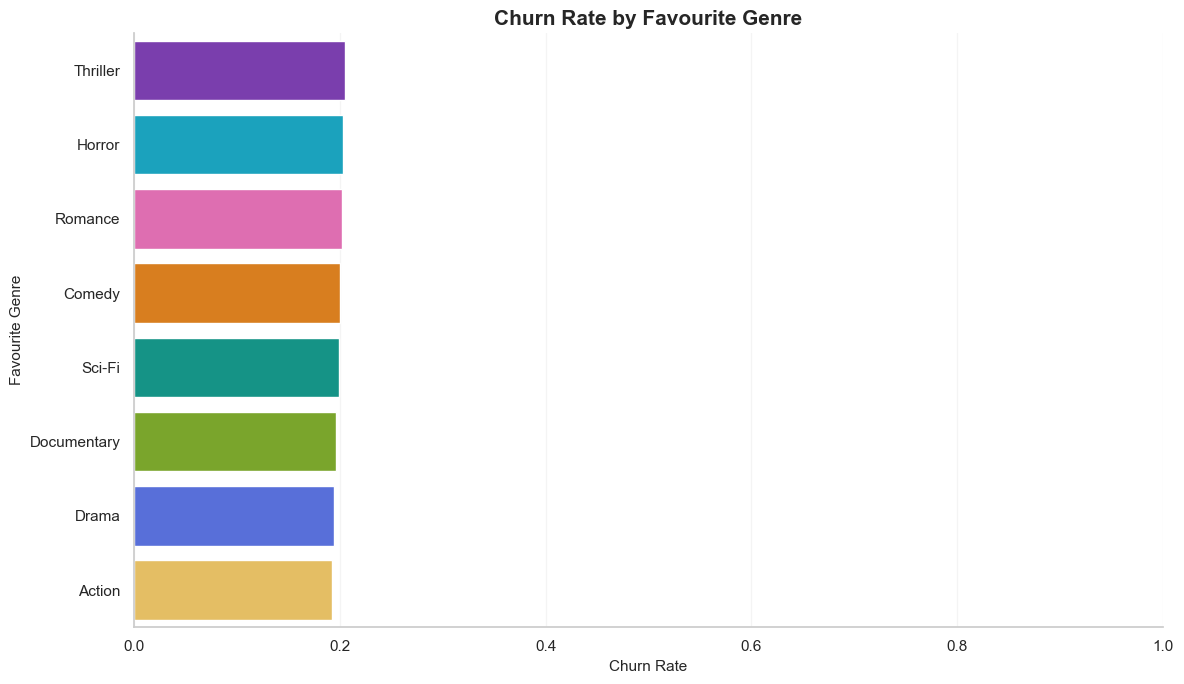

In [11]:
# Churn rate by favourite genre

genre_churn = (
    df.groupby("favorite_genre")["churn"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=genre_churn.values,
    y=genre_churn.index,
    palette=PALETTE
)

plt.title("Churn Rate by Favourite Genre")
plt.xlabel("Churn Rate")
plt.ylabel("Favourite Genre")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

11. Device usage analysis

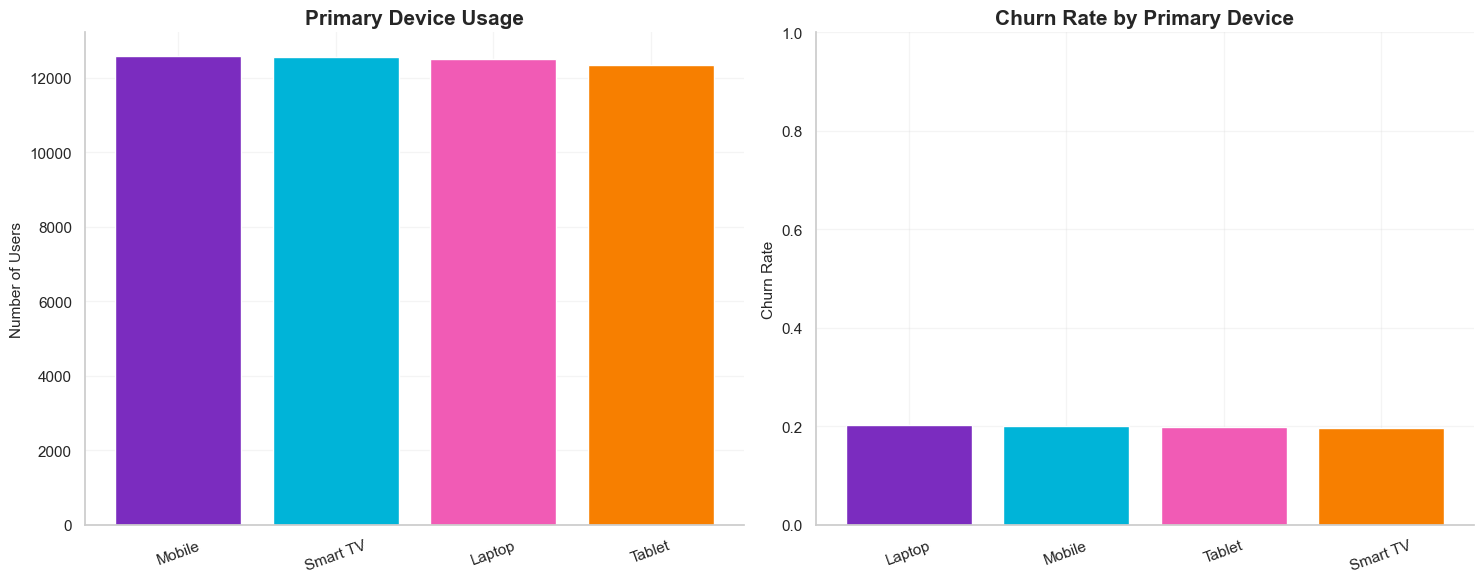

In [12]:
# ============================================================
# 11. DEVICE USAGE ANALYSIS
# ============================================================

device_counts = df["primary_device"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].bar(
    device_counts.index,
    device_counts.values,
    color=PALETTE[:len(device_counts)]
)

axes[0].set_title("Primary Device Usage")
axes[0].set_ylabel("Number of Users")
axes[0].tick_params(axis="x", rotation=20)

device_churn = (
    df.groupby("primary_device")["churn"]
    .mean()
    .sort_values(ascending=False)
)

axes[1].bar(
    device_churn.index,
    device_churn.values,
    color=PALETTE[:len(device_churn)]
)

axes[1].set_title("Churn Rate by Primary Device")
axes[1].set_ylabel("Churn Rate")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

12. Correlation analysis

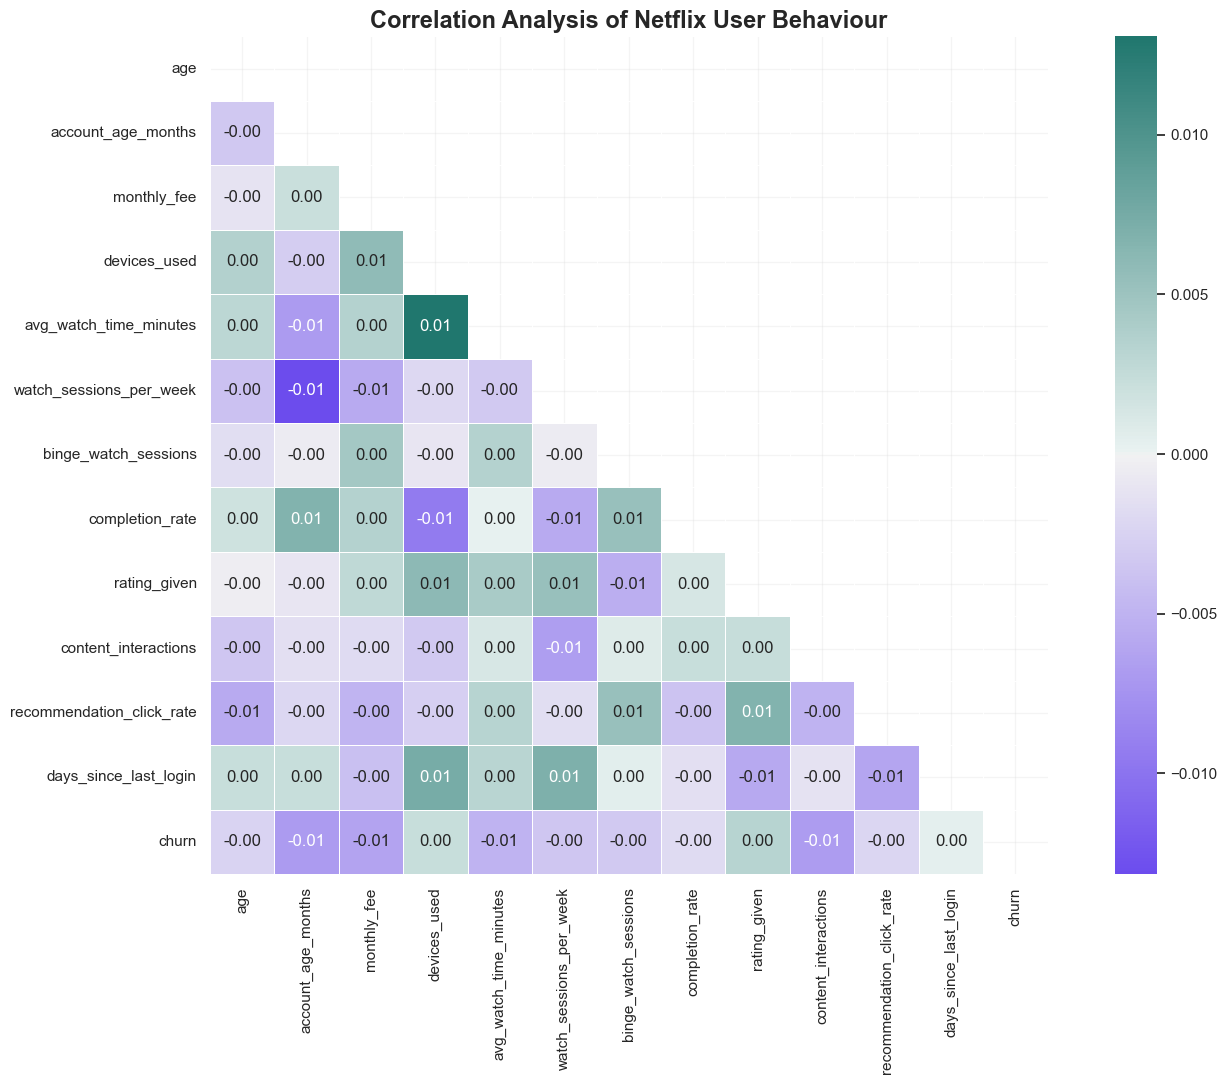

In [13]:
# ============================================================
# 12. CORRELATION HEATMAP
# ============================================================

numeric_data = df.select_dtypes(include=np.number)

correlation = numeric_data.corr()

plt.figure(figsize=(15, 11))

mask = np.triu(np.ones_like(correlation, dtype=bool))

sns.heatmap(
    correlation,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap=sns.diverging_palette(
        270,
        180,
        s=90,
        l=45,
        as_cmap=True
    ),
    center=0,
    linewidths=0.5,
    square=True
)

plt.title(
    "Correlation Analysis of Netflix User Behaviour",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

13. User segmentation using K-Means

In [14]:
# ============================================================
# 13. USER SEGMENTATION
# ============================================================

segmentation_features = [
    "avg_watch_time_minutes",
    "watch_sessions_per_week",
    "binge_watch_sessions",
    "completion_rate",
    "content_interactions",
    "recommendation_click_rate",
    "days_since_last_login",
    "devices_used"
]

segment_data = df[segmentation_features].copy()

# Impute missing numerical values
segment_data = segment_data.fillna(
    segment_data.median()
)

# Scale features
segment_scaler = StandardScaler()

X_segment = segment_scaler.fit_transform(segment_data)

print("Segmentation data prepared.")
print("Number of features:", X_segment.shape[1])

Segmentation data prepared.
Number of features: 8


14. Find the optimal number of clusters

  File "C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


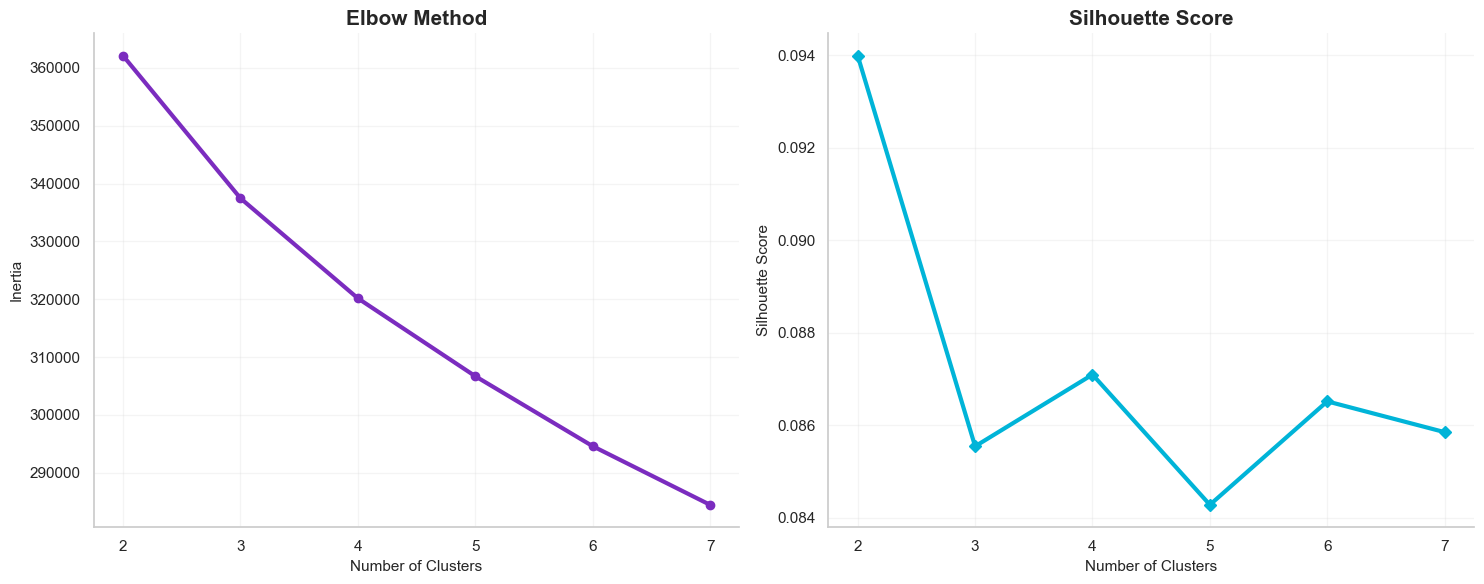

,Clusters,Inertia,Silhouette Score
0,2,362094.502863,0.093993
1,3,337457.085210,0.085542
2,4,320162.172506,0.087095
3,5,306693.954319,0.084277
4,6,294597.005259,0.086515
5,7,284456.383951,0.085849


In [15]:
# ============================================================
# 14. ELBOW METHOD AND SILHOUETTE ANALYSIS
# ============================================================

k_values = range(2, 8)

inertia_values = []
silhouette_values = []

# Sample for faster silhouette calculation
rng = np.random.RandomState(RANDOM_STATE)

sample_size = min(5000, len(X_segment))
sample_indices = rng.choice(
    len(X_segment),
    size=sample_size,
    replace=False
)

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = model.fit_predict(X_segment)

    inertia_values.append(model.inertia_)

    silhouette_values.append(
        silhouette_score(
            X_segment[sample_indices],
            labels[sample_indices]
        )
    )

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].plot(
    list(k_values),
    inertia_values,
    marker="o",
    linewidth=3,
    color=COLORS["purple"]
)

axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    list(k_values),
    silhouette_values,
    marker="D",
    linewidth=3,
    color=COLORS["cyan"]
)

axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

display(
    pd.DataFrame({
        "Clusters": list(k_values),
        "Inertia": inertia_values,
        "Silhouette Score": silhouette_values
    })
)

15. Train K-Means model

In [16]:
# ============================================================
# 15. K-MEANS CLUSTERING
# ============================================================

best_k = list(k_values)[np.argmax(silhouette_values)]

kmeans = KMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    n_init=10
)

df["engagement_segment"] = kmeans.fit_predict(
    X_segment
)

df["engagement_segment"] = df["engagement_segment"].astype(str)

print("Selected number of clusters:", best_k)

display(
    df["engagement_segment"]
    .value_counts()
    .sort_index()
    .to_frame("Number of Users")
)

Selected number of clusters: 2


,Number of Users
engagement_segment,
0,24941
1,25059


16. Segment profiling

In [17]:
# ============================================================
# 16. SEGMENT PROFILING
# ============================================================

segment_profile = df.groupby(
    "engagement_segment"
)[segmentation_features].mean()

segment_profile["user_count"] = (
    df.groupby("engagement_segment").size()
)

segment_profile["user_percentage"] = (
    segment_profile["user_count"] / len(df) * 100
)

display(segment_profile.round(2))

,avg_watch_time_minutes,watch_sessions_per_week,binge_watch_sessions,completion_rate,content_interactions,recommendation_click_rate,days_since_last_login,devices_used,user_count,user_percentage
engagement_segment,,,,,,,,,,
0,130.13,10.06,7.0,64.95,24.26,49.76,29.03,1.33,24941,49.88
1,179.65,9.91,7.0,64.12,24.35,49.37,29.79,2.67,25059,50.12


17. Segment visualisation

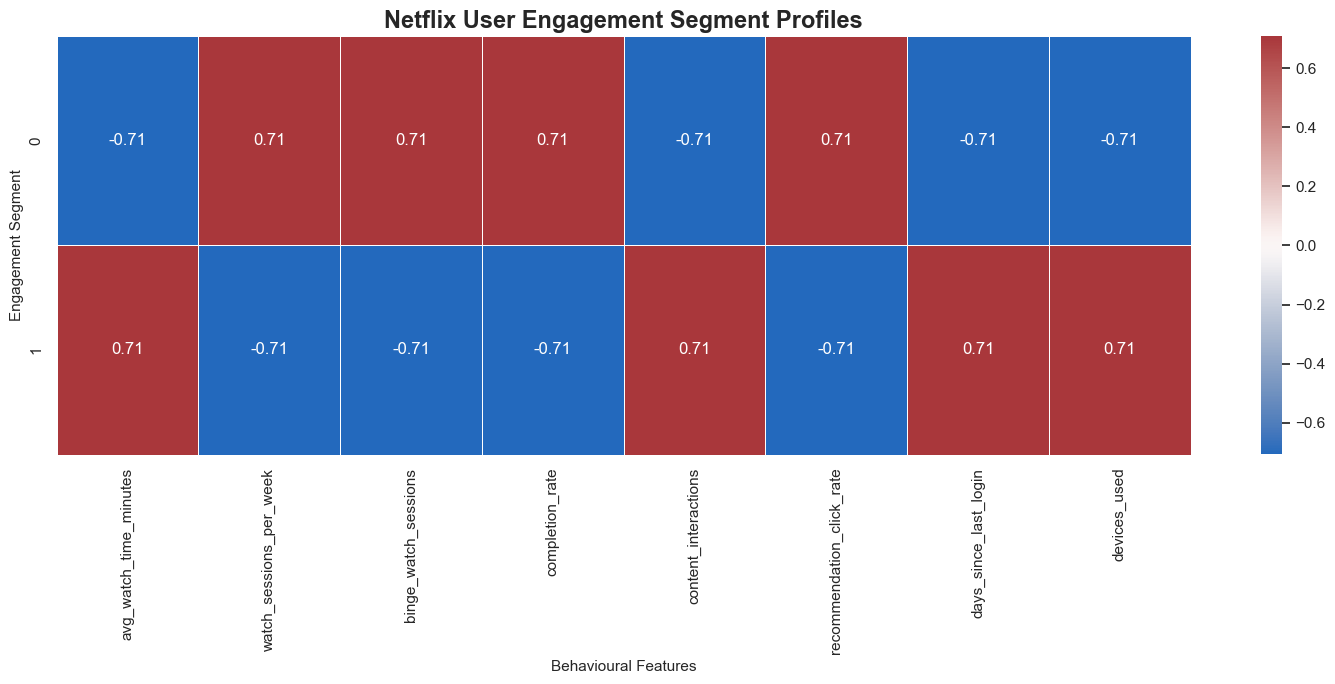

In [18]:
# ============================================================
# 17. SEGMENT PROFILE HEATMAP
# ============================================================

profile_standardised = (
    segment_profile[segmentation_features]
    - segment_profile[segmentation_features].mean()
) / segment_profile[segmentation_features].std()

plt.figure(figsize=(15, 7))

sns.heatmap(
    profile_standardised,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    linewidths=0.7
)

plt.title(
    "Netflix User Engagement Segment Profiles",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("Behavioural Features")
plt.ylabel("Engagement Segment")

plt.tight_layout()
plt.show()

18.PCA cluster visualisation

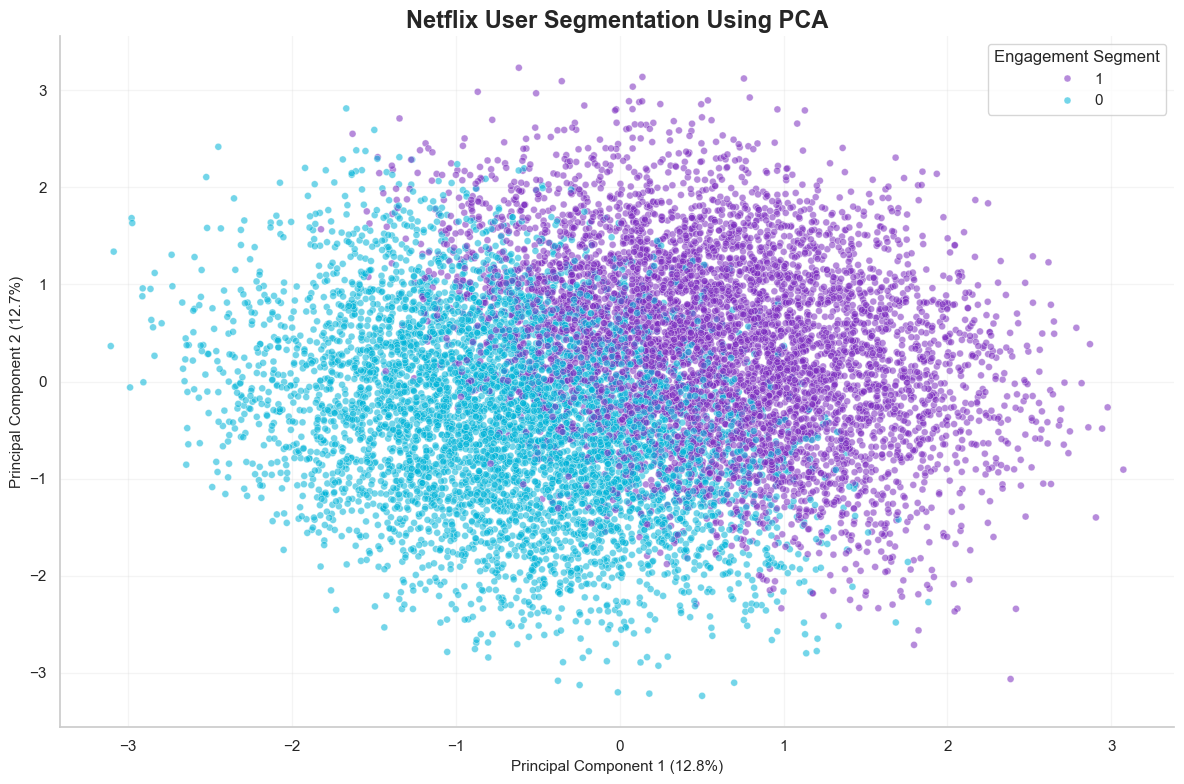

In [19]:
# ============================================================
# 18. PCA VISUALISATION
# ============================================================

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_segment)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Segment": df["engagement_segment"].values
})

# Sample for readable plotting
plot_data = pca_df.sample(
    min(12000, len(pca_df)),
    random_state=RANDOM_STATE
)

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=plot_data,
    x="PC1",
    y="PC2",
    hue="Segment",
    palette=PALETTE[:best_k],
    alpha=0.55,
    s=25
)

plt.title(
    "Netflix User Segmentation Using PCA",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel(
    f"Principal Component 1 ({pca.explained_variance_ratio_[0]:.1%})"
)

plt.ylabel(
    f"Principal Component 2 ({pca.explained_variance_ratio_[1]:.1%})"
)

plt.legend(title="Engagement Segment")

plt.tight_layout()
plt.show()

19. Churn rate across segments

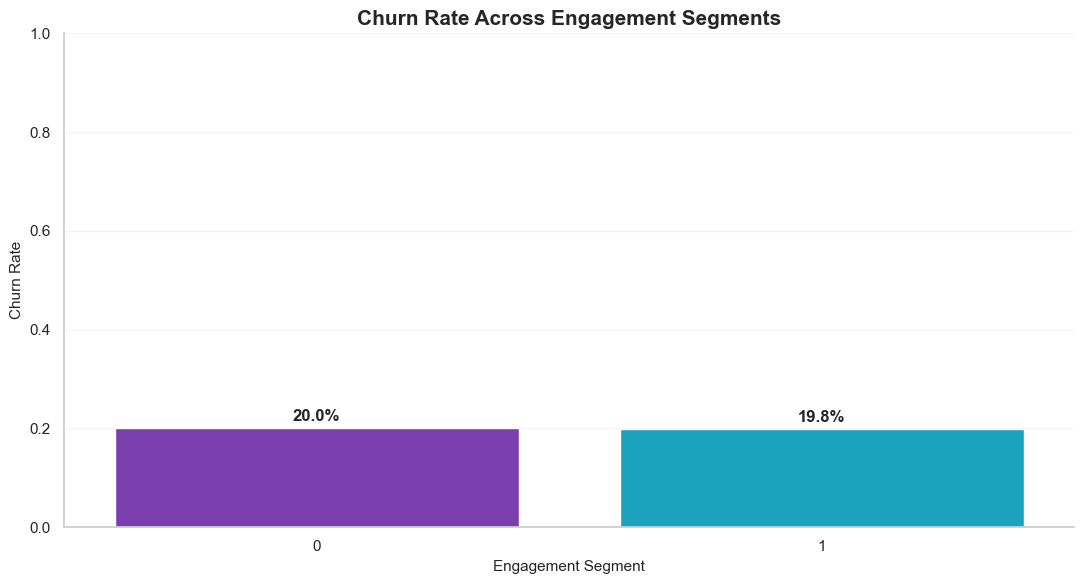

In [20]:
# ============================================================
# 19. CHURN RATE BY ENGAGEMENT SEGMENT
# ============================================================

segment_churn = (
    df.groupby("engagement_segment")["churn"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=segment_churn.index,
    y=segment_churn.values,
    palette=PALETTE[:len(segment_churn)]
)

ax.set_title("Churn Rate Across Engagement Segments")
ax.set_xlabel("Engagement Segment")
ax.set_ylabel("Churn Rate")
ax.set_ylim(0, 1)

for i, value in enumerate(segment_churn.values):
    ax.text(
        i,
        value + 0.015,
        f"{value:.1%}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

20. Churn prediction using Machine Learning


In [21]:
# ============================================================
# 20. PREPARE MACHINE LEARNING DATA
# ============================================================

# Remove identifier, target text and target itself
excluded_columns = [
    "user_id",
    "churned",
    "churn",
    "engagement_segment"
]

X = df.drop(
    columns=excluded_columns,
    errors="ignore"
)

y = df["churn"].astype(int)

# Identify numerical and categorical features
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Numerical features: ['age', 'account_age_months', 'monthly_fee', 'devices_used', 'avg_watch_time_minutes', 'watch_sessions_per_week', 'binge_watch_sessions', 'completion_rate', 'rating_given', 'content_interactions', 'recommendation_click_rate', 'days_since_last_login']
Categorical features: ['gender', 'country', 'subscription_type', 'payment_method', 'primary_device', 'favorite_genre']
Training data: (40000, 18)
Testing data: (10000, 18)


21. Preprocessing pipeline

In [22]:
# ============================================================
# 21. PREPROCESSING PIPELINE
# ============================================================

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

22. Build machine learning models

In [23]:
# ============================================================
# 22. MODEL CREATION
# ============================================================

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=350,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=350,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

pipelines = {
    name: Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])
    for name, model in models.items()
}

print("All machine learning models created.")

All machine learning models created.


23. Cross-validation

In [24]:
# ============================================================
# 23. CROSS VALIDATION
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

cv_results = []

for name, model in pipelines.items():

    print("Evaluating:", name)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC AUC": scores["test_roc_auc"].mean(),
        "PR AUC": scores["test_average_precision"].mean()
    })

cv_results = pd.DataFrame(cv_results)

display(
    cv_results.sort_values(
        "ROC AUC",
        ascending=False
    ).round(4)
)

Evaluating: Logistic Regression
Evaluating: Random Forest
Evaluating: Extra Trees


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
0,Logistic Regression,0.5068,0.2008,0.4948,0.2856,0.5059,0.2036
2,Extra Trees,0.7998,0.1378,0.0008,0.0015,0.4992,0.1998
1,Random Forest,0.8007,0.0000,0.0000,0.0000,0.4985,0.1995


24. Train and evaluate models

In [25]:
# ============================================================
# 24. MODEL TRAINING AND TESTING
# ============================================================

fitted_models = {}
predictions = {}
probabilities = {}

test_results = []

for name, model in pipelines.items():

    print("Training:", name)

    model.fit(X_train, y_train)

    fitted_models[name] = model

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_prob

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_prob),
        "PR AUC": average_precision_score(y_test, y_prob)
    })

test_results = pd.DataFrame(test_results)

display(
    test_results.sort_values(
        "ROC AUC",
        ascending=False
    ).round(4)
)

Training: Logistic Regression
Training: Random Forest
Training: Extra Trees


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
1,Random Forest,0.8007,0.5000,0.0000,0.0000,0.0000,0.4988,0.1964
2,Extra Trees,0.7998,0.4998,0.1538,0.0010,0.0020,0.4947,0.1965
0,Logistic Regression,0.5056,0.4953,0.1962,0.4782,0.2782,0.4916,0.1916


25. Model comparison visualisation

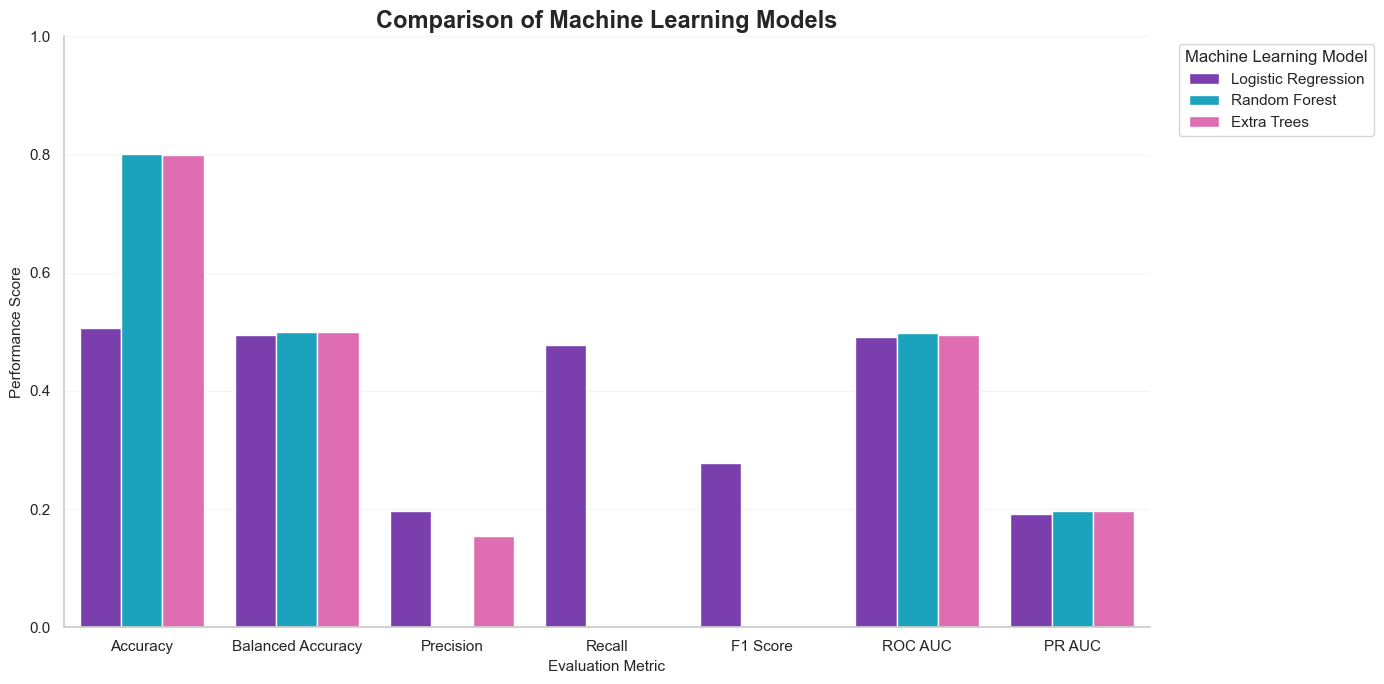

In [26]:
# ============================================================
# 25. MODEL COMPARISON
# ============================================================

comparison = test_results.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=comparison,
    x="Metric",
    y="Score",
    hue="Model",
    palette=PALETTE[:len(models)]
)

plt.title(
    "Comparison of Machine Learning Models",
    fontsize=17,
    fontweight="bold"
)

plt.ylabel("Performance Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)

plt.legend(
    title="Machine Learning Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

26. Confusion matrix

Best model: Logistic Regression
              precision    recall  f1-score   support

    Retained       0.80      0.51      0.62      8007
     Churned       0.20      0.48      0.28      1993

    accuracy                           0.51     10000
   macro avg       0.50      0.50      0.45     10000
weighted avg       0.68      0.51      0.56     10000



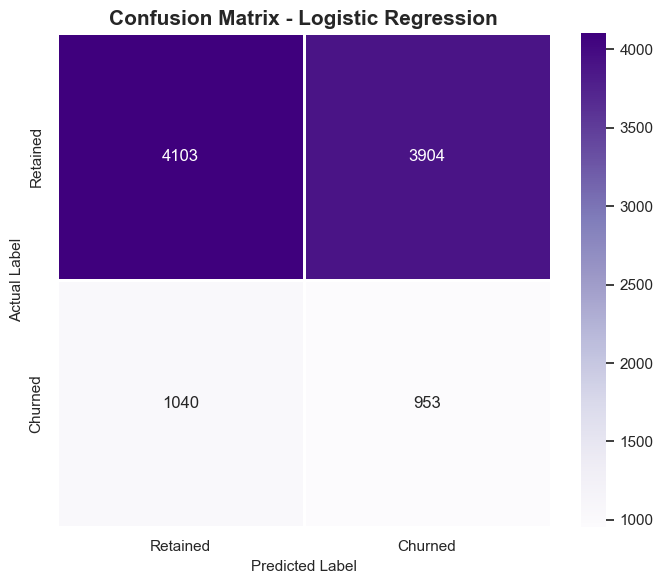

In [27]:
# ============================================================
# 26. CONFUSION MATRIX
# ============================================================

best_model_name = (
    cv_results.sort_values("ROC AUC", ascending=False)
    .iloc[0]["Model"]
)

best_model = fitted_models[best_model_name]

best_prediction = predictions[best_model_name]

print("Best model:", best_model_name)

print(
    classification_report(
        y_test,
        best_prediction,
        target_names=["Retained", "Churned"],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_test,
    best_prediction
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    linewidths=1,
    xticklabels=["Retained", "Churned"],
    yticklabels=["Retained", "Churned"]
)

plt.title("Confusion Matrix - " + best_model_name)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

27. ROC curve

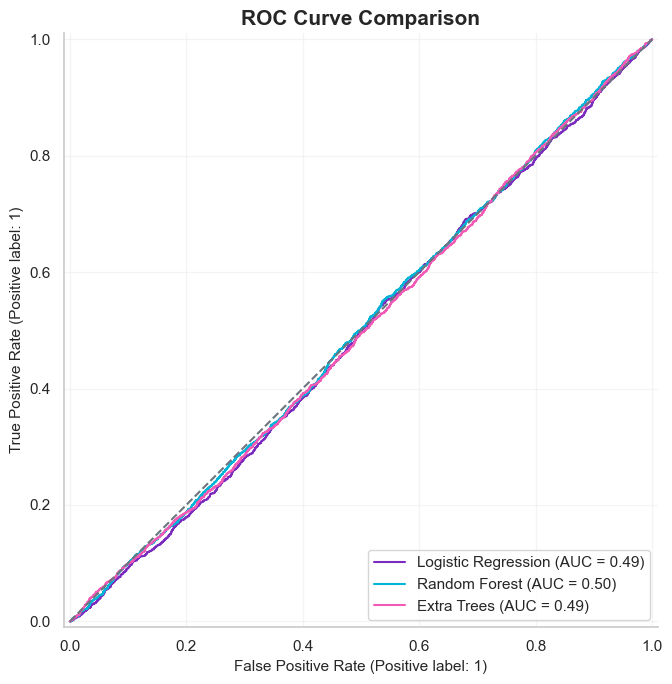

In [30]:
# ============================================================
# 27. ROC CURVE COMPARISON
# ============================================================

plt.figure(figsize=(10, 7))

for (name, probability), color in zip(
    probabilities.items(),
    PALETTE
):

    RocCurveDisplay.from_predictions(
        y_test,
        probability,
        name=name,
        ax=plt.gca(),
       
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color=COLORS["grey"]
)

plt.title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

28. Precision-recall curve

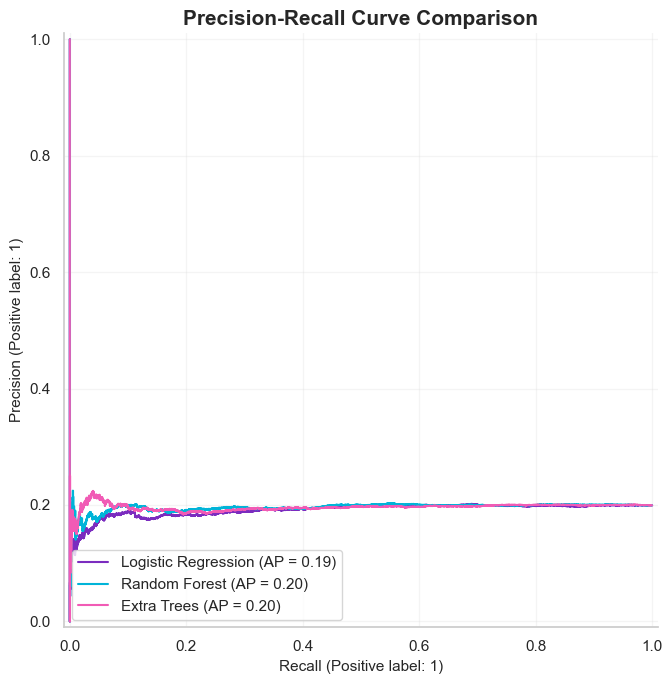

In [31]:
# ============================================================
# 28. PRECISION-RECALL CURVE
# ============================================================

plt.figure(figsize=(10, 7))

for (name, probability), color in zip(
    probabilities.items(),
    PALETTE
):

    PrecisionRecallDisplay.from_predictions(
        y_test,
        probability,
        name=name,
        ax=plt.gca(),
        color=color
    )

plt.title("Precision-Recall Curve Comparison")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 30. BEHAVIOURAL COMPARISON
# ============================================================

behaviour_features = [
    "avg_watch_time_minutes",
    "watch_sessions_per_week",
    "completion_rate",
    "content_interactions",
    "recommendation_click_rate",
    "days_since_last_login"
]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, feature in zip(
    axes.flatten(),
    behaviour_features
):

    sns.boxplot(
        data=df,
        x="churned",
        y=feature,
        hue="churned",
        palette={
            "No": COLORS["cyan"],
            "Yes": COLORS["pink"]
        },
        legend=False,
        ax=ax
    )

    ax.set_title(
        feature.replace("_", " ").title()
    )

    ax.set_xlabel("Churn Status")

plt.suptitle(
    "Behavioural Differences Between Churned and Retained Users",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

,Feature,Importance,Standard Deviation
4,subscription_type,0.0014,0.0016
9,favorite_genre,0.0012,0.0022
10,avg_watch_time_minutes,0.0010,0.0010
1,gender,0.0008,0.0010
15,content_interactions,0.0007,0.0011
8,devices_used,0.0005,0.0002
7,primary_device,0.0004,0.0018
12,binge_watch_sessions,0.0003,0.0006
5,monthly_fee,0.0002,0.0012
13,completion_rate,0.0000,0.0000


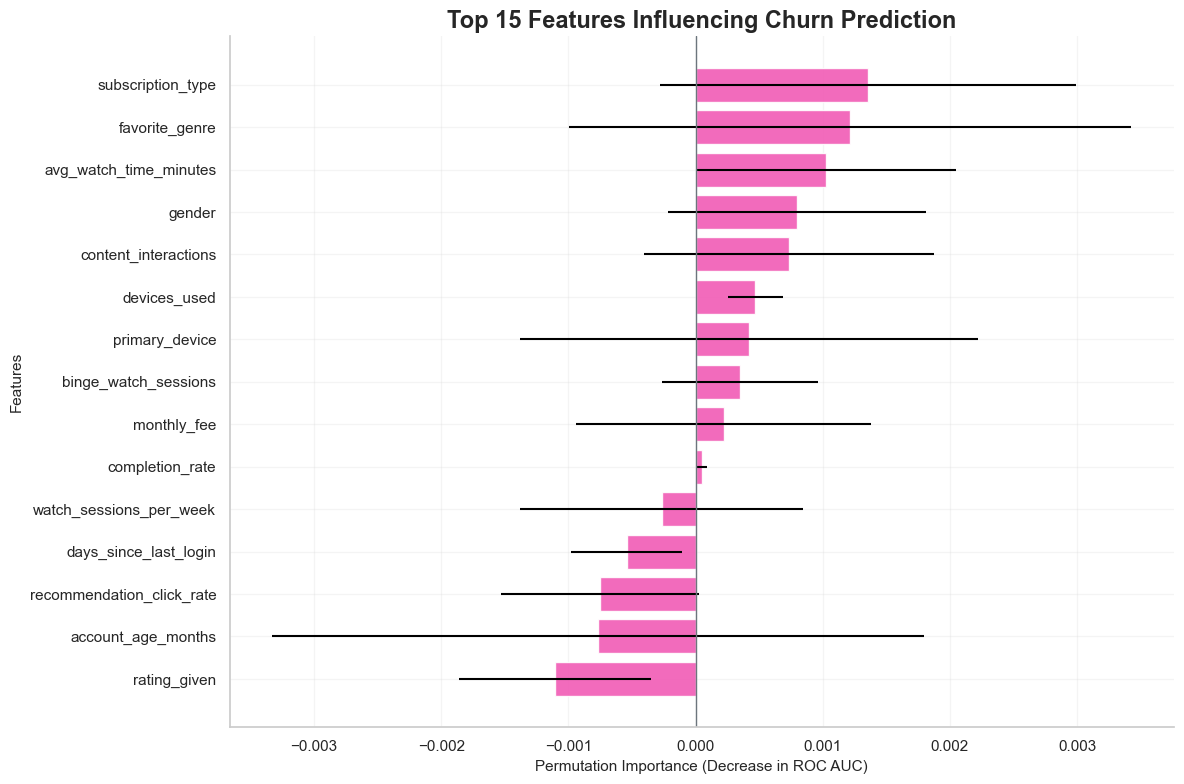

In [32]:
# ============================================================
# 29. PERMUTATION FEATURE IMPORTANCE
# ============================================================

importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=8,
    random_state=RANDOM_STATE,
    scoring="roc_auc",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Standard Deviation": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

display(importance_df.head(15).round(4))

top_features = importance_df.head(15).sort_values(
    "Importance"
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    xerr=top_features["Standard Deviation"],
    color=COLORS["pink"],
    alpha=0.9
)

plt.axvline(
    0,
    color=COLORS["grey"],
    linewidth=1
)

plt.title(
    "Top 15 Features Influencing Churn Prediction",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("Permutation Importance (Decrease in ROC AUC)")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 30. BEHAVIOURAL COMPARISON
# ============================================================

behaviour_features = [
    "avg_watch_time_minutes",
    "watch_sessions_per_week",
    "completion_rate",
    "content_interactions",
    "recommendation_click_rate",
    "days_since_last_login"
]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, feature in zip(
    axes.flatten(),
    behaviour_features
):

    sns.boxplot(
        data=df,
        x="churned",
        y=feature,
        hue="churned",
        palette={
            "No": COLORS["cyan"],
            "Yes": COLORS["pink"]
        },
        legend=False,
        ax=ax
    )

    ax.set_title(
        feature.replace("_", " ").title()
    )

    ax.set_xlabel("Churn Status")

plt.suptitle(
    "Behavioural Differences Between Churned and Retained Users",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

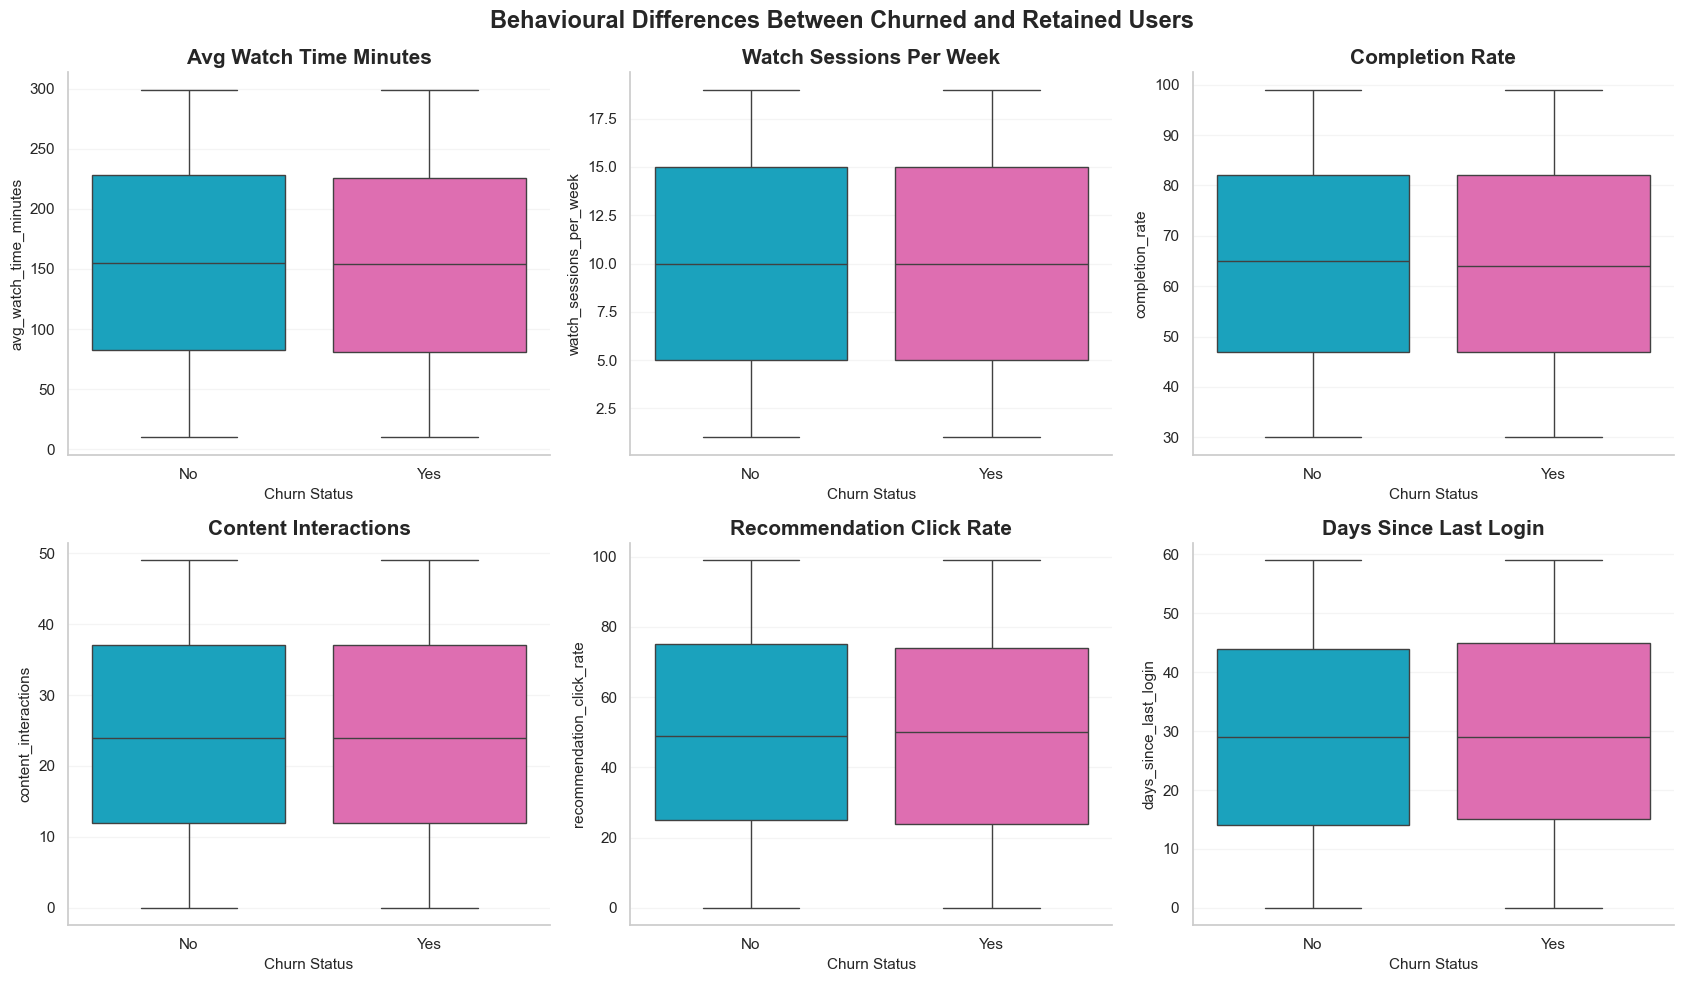

In [33]:
# ============================================================
# 30. BEHAVIOURAL COMPARISON
# ============================================================

behaviour_features = [
    "avg_watch_time_minutes",
    "watch_sessions_per_week",
    "completion_rate",
    "content_interactions",
    "recommendation_click_rate",
    "days_since_last_login"
]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, feature in zip(
    axes.flatten(),
    behaviour_features
):

    sns.boxplot(
        data=df,
        x="churned",
        y=feature,
        hue="churned",
        palette={
            "No": COLORS["cyan"],
            "Yes": COLORS["pink"]
        },
        legend=False,
        ax=ax
    )

    ax.set_title(
        feature.replace("_", " ").title()
    )

    ax.set_xlabel("Churn Status")

plt.suptitle(
    "Behavioural Differences Between Churned and Retained Users",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 31. FINAL PROJECT SUMMARY
# ============================================================

overall_churn = df["churn"].mean() * 100

best_test_result = (
    test_results[
        test_results["Model"] == best_model_name
    ].iloc[0]
)

print("=" * 65)
print("NETFLIX USER BEHAVIOUR - MACHINE LEARNING SUMMARY")
print("=" * 65)

print(f"Total users analysed: {len(df):,}")

print(f"Number of features: {len(X.columns)}")

print(f"Overall churn rate: {overall_churn:.2f}%")

print(f"Number of engagement segments: {best_k}")

print("-" * 65)

print("BEST PREDICTIVE MODEL")

print("Model:", best_model_name)

print(f"Accuracy: {best_test_result['Accuracy']:.4f}")

print(f"Precision: {best_test_result['Precision']:.4f}")

print(f"Recall: {best_test_result['Recall']:.4f}")

print(f"F1 Score: {best_test_result['F1 Score']:.4f}")

print(f"ROC AUC: {best_test_result['ROC AUC']:.4f}")

print("-" * 65)

print("TOP FIVE PREDICTIVE FEATURES")

display(importance_df.head(5))

print("=" * 65)

In [34]:
# ============================================================
# 32. EXPORT PROJECT RESULTS
# ============================================================

output_folder = Path("netflix_ml_outputs")
output_folder.mkdir(exist_ok=True)

# Export segmented dataset
df.to_csv(
    output_folder / "users_with_engagement_segments.csv",
    index=False
)

# Export segment profiles
segment_profile.to_csv(
    output_folder / "engagement_segment_profiles.csv"
)

# Export model results
cv_results.to_csv(
    output_folder / "cross_validation_results.csv",
    index=False
)

test_results.to_csv(
    output_folder / "model_test_results.csv",
    index=False
)

# Export feature importance
importance_df.to_csv(
    output_folder / "feature_importance.csv",
    index=False
)

print("All project outputs exported successfully.")

print("Output directory:", output_folder.resolve())

All project outputs exported successfully.
Output directory: C:\Users\kapil\Downloads\poject\netflix-user-behaviour-dataset-main\netflix-user-behaviour-dataset-main\netflix_ml_outputs
